# **Deel 1 - Les 3 - Regularisatie, Cross Validation en Grid Search**

## Stap 1: Libraries

In [5]:
# Stap 1: Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge, Lasso, ElasticNet, LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import os

## Stap 2: Data

In [6]:
df_advertising = pd.read_csv("Advertising_extended.csv")

In [7]:
df_advertising.head(10)

,TV,radio,newspaper,billboard_ads,social_clicks,email_campaigns,influencer_budget,flyer_distribution,event_sponsorship,banner_impressions,podcast_ads,store_visitors,avg_temperature,competitor_ad_spend,promo_merchandise,sales
0,230.1,37.8,69.2,232.6,476.1,25.7,19.2,76.1,106.4,229.5,7.9,419.8,20.4,113.8,55.8,22.1
1,44.5,39.3,45.1,149.6,422.9,41.7,19.9,65.0,38.8,179.8,16.6,708.5,14.2,175.6,17.3,10.4
2,17.2,45.9,69.3,162.4,433.5,51.2,19.4,62.2,66.2,139.6,22.6,358.4,26.0,221.3,41.4,9.3
3,151.5,41.3,58.5,139.1,277.2,38.8,34.0,82.3,75.3,224.1,22.3,507.9,10.3,145.6,42.3,18.5
4,180.8,10.8,58.4,149.0,450.9,29.4,31.1,103.0,36.6,163.8,11.2,528.0,24.7,127.6,39.1,12.9
5,8.7,48.9,75.0,110.4,378.0,79.8,19.3,75.6,44.7,192.8,16.1,560.1,24.6,140.8,41.0,7.2
6,57.5,32.8,23.5,84.5,311.4,51.6,48.4,44.0,63.8,194.3,11.9,479.9,19.2,157.5,25.5,11.8
7,120.2,19.6,11.6,146.8,280.4,51.4,23.0,90.7,63.0,204.7,2.4,443.4,20.8,145.4,31.3,13.2
8,8.6,2.1,1.0,38.1,343.2,32.0,23.3,65.1,85.8,244.3,16.0,443.7,13.7,129.3,26.4,4.8
9,199.8,2.6,21.2,154.3,178.1,36.3,26.3,74.5,59.4,139.8,21.0,367.3,18.6,111.2,47.6,10.6


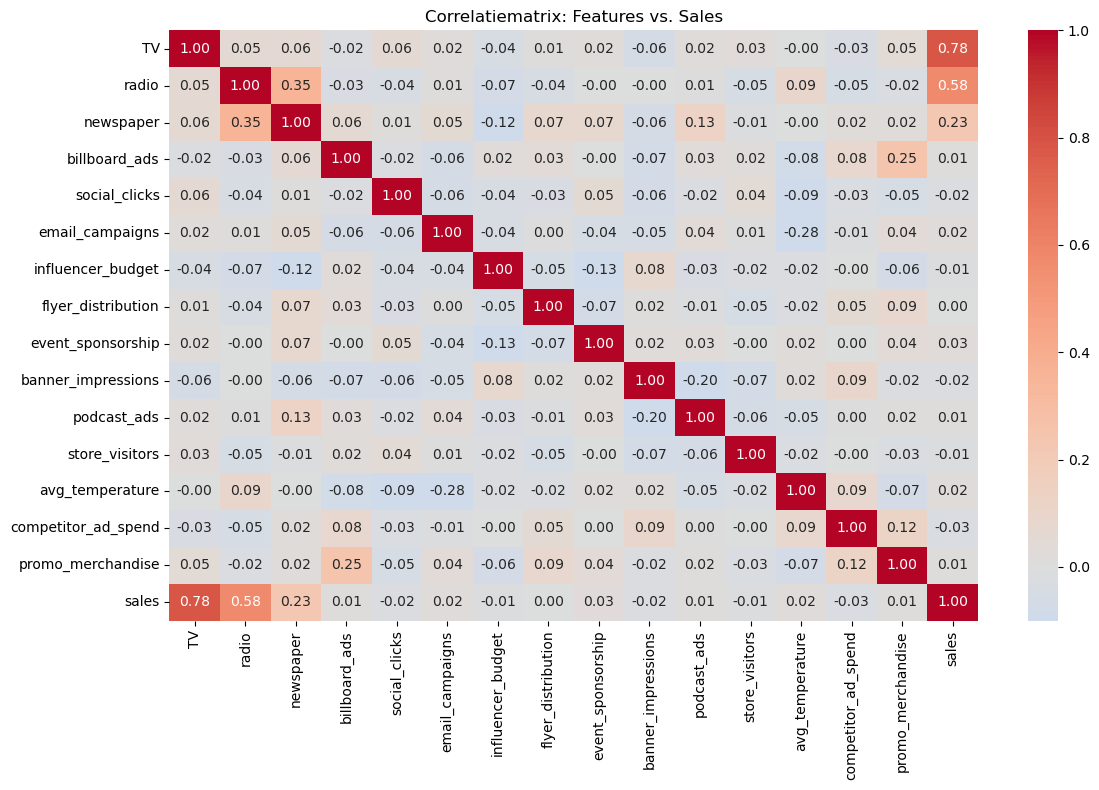

In [8]:
plt.figure(figsize=(12, 8))
sns.heatmap(df_advertising.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-0.1,
    vmax=1.0,
    center=0,
)
plt.title("Correlatiematrix: Features vs. Sales")
plt.tight_layout()
plt.show()

In [9]:
df_advertising.columns

Index(['TV', 'radio', 'newspaper', 'billboard_ads', 'social_clicks',
       'email_campaigns', 'influencer_budget', 'flyer_distribution',
       'event_sponsorship', 'banner_impressions', 'podcast_ads',
       'store_visitors', 'avg_temperature', 'competitor_ad_spend',
       'promo_merchandise', 'sales'],
      dtype='object')

## Stap 3: Preprocessing

In [10]:
target = "sales"
features_num = [
    "TV", "radio", "newspaper"
]


num_pipeline = Pipeline(steps = [
    (...)
])

preprocessor = ColumnTransformer(transformers=[
    (...),
])

preprocessor

ColumnTransformer(transformers=[Ellipsis])

## Stap 4: Splitsen in Train en Test

In [11]:
X = df_advertising[features_num]
y = df_advertising[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Grootte Trainset: {X_train.shape[0]} | Testset: {X_test.shape[0]} ")

Grootte Trainset: 160 | Testset: 40 


## Stap 5: ML Pipeline

In [12]:
# 1. Pipeline voor Lineaire Regressie
pipe_lr = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression())
])

# 2. Pipeline voor Ridge Regressie
pipe_ridge = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", Ridge(alpha=10.0))
])
    # alpha staat voor de regularisatieparameter die de mate van regularisatie bepaalt.
    # Een hogere waarde van alpha betekent meer regularisatie, wat kan helpen om overfitting te verminderen, maar kan ook leiden tot een slechtere fit als het te hoog is.

# 3. Pipeline voor Lasso Regressie
pipe_lasso = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", Lasso(alpha=0.5))
])


## Stap 6: Train het model

In [13]:
pipe_lr.fit(X_train, y_train)
print("Pipeline Lineaire Regressie succesvol getraind!")
pipe_ridge.fit(X_train, y_train)
print("Pipeline Ridge Regressie succesvol getraind!")
pipe_lasso.fit(X_train, y_train)
print("Pipeline Lasso Regressie succesvol getraind!")

pipe_lasso


Pipeline Lineaire Regressie succesvol getraind!
Pipeline Ridge Regressie succesvol getraind!
Pipeline Lasso Regressie succesvol getraind!


Pipeline(steps=[('scaler', StandardScaler()), ('regressor', Lasso(alpha=0.5))])

## Stap 7: Evaluatie

     Feature     OLS  Ridge (L2)  Lasso (L1)
0         TV  3.7642      3.5506      3.2897
1      radio  2.7923      2.6150      2.3396
2  newspaper  0.0560      0.1213      0.0000


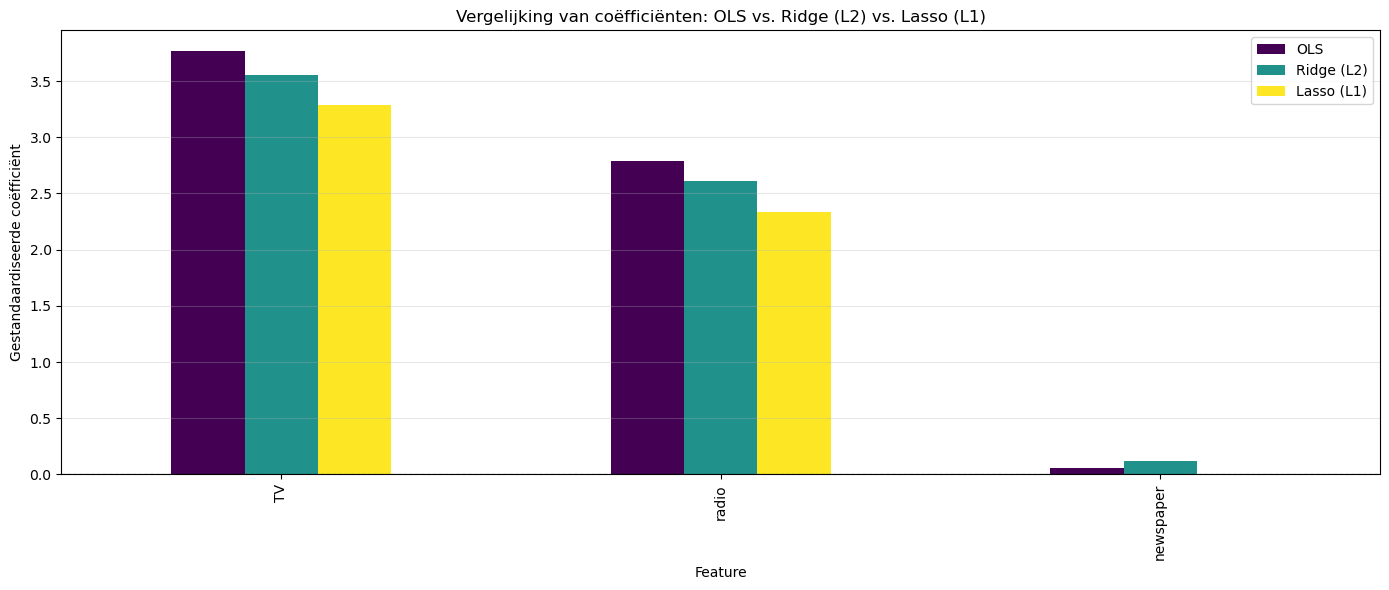

In [14]:
comparison = pd.DataFrame(
    {
        "Feature": X.columns,
        "OLS": pipe_lr.named_steps["regressor"].coef_,
        "Ridge (L2)": pipe_ridge.named_steps["regressor"].coef_,
        "Lasso (L1)": pipe_lasso.named_steps["regressor"].coef_,
    }
)

print(comparison.round(4))

# 6. Barplot van coëfficiënten per model
comparison.set_index("Feature").plot(
    kind="bar", figsize=(14, 6), colormap="viridis"
)
plt.axhline(0, color="black", linestyle="--", linewidth=0.8)
plt.title("Vergelijking van coëfficiënten: OLS vs. Ridge (L2) vs. Lasso (L1)")
plt.ylabel("Gestandaardiseerde coëfficiënt")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Stap 6: Train het model (met GridSearch en Cross Validation)

**Uitleg:**  
  
In plaats van een willekeurige waarde voor de boeteterm $\alpha$ (alpha) en de verhouding tussen L1- en L2-boete (`l1_ratio`) te kiezen, voeren we een Grid Search met Cross-Validation (`GridSearchCV`) uit:
  
* We bepalen een rooster (**param_grid**) met mogelijke waarden voor `alpha` en `l1_ratio`.
* `GridSearchCV` splitst de trainingsdata intern op in *$k$* folds (bijv. 5-voudige CV), traint de volledige pipeline op *$k-1$* folds en evalueert op de overblijvende fold.
* De beste combinatie van hyperparameters wordt automatisch geselecteerd op basis van de laagste Mean Squared Error (MSE).
* Vervolgens fit de beste estimator zich automatisch op de gehele trainingset.

In [15]:
# Stap 5: ML Pipeline
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ('elastic_net', ElasticNet(max_iter=10000, random_state=42))
])

# Toon de opbouw van de pipeline
pipeline

Pipeline(steps=[('scaler', StandardScaler()),
                ('elastic_net', ElasticNet(max_iter=10000, random_state=42))])

In [16]:
# Stap 6: Train het model met Grid Search & CV
# Parameterrooster voor ElasticNet
param_grid = {
    "elastic_net__alpha": [0.01, 0.05, 0.1, 0.2, 0.5, 1.0, 5.0, 10.0],
    "elastic_net__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.8, 0.9, 0.95, 0.99, 1.0],
}

# 5-fold cross-validation grid search opzetten
grid_model = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring='neg_mean_squared_error',
    cv=5,
    verbose=1
)

# Trainen op de trainingsdata
grid_model.fit(X_train, y_train)

print("Model training & Grid Search voltooid!")
print(f"Beste hyperparameters: {grid_model.best_params_}")

# Inspecteer de coëfficiënten van het beste model
best_enet = grid_model.best_estimator_.named_steps["elastic_net"]
coef_df = pd.DataFrame(
    {"Feature": X.columns, "Coëfficiënt": best_enet.coef_}
).sort_values(by="Coëfficiënt", ascending=False)

print("\n--- GEVONDEN COËFFICIËNTEN ---")
print(coef_df.round(4).to_string(index=False))

Fitting 5 folds for each of 72 candidates, totalling 360 fits
Model training & Grid Search voltooid!
Beste hyperparameters: {'elastic_net__alpha': 0.05, 'elastic_net__l1_ratio': 1.0}

--- GEVONDEN COËFFICIËNTEN ---
  Feature  Coëfficiënt
       TV       3.7167
    radio       2.7589
newspaper       0.0198


## Stap 7: Evaluatie

**Uitleg:**  
  
We evalueren het beste model op de testset (`X_test`), die het model nog nooit gezien heeft.   Omdat het hier om een regressieprobleem gaat (voorspellen van `sales`), gebruiken we:
* **MAE (Mean Absolute Error):** De gemiddelde absolute afwijking van de voorspelling.
* **RMSE (Root Mean Squared Error):** De wortel van de gemiddelde kwadratische fout (gevoeliger voor grote uitschieters).
* **$R^2$-score:** Het percentage verklaarde variantie van de verkoopcijfers.

In [17]:
# Stap 7: Evaluatie
# Voorspellingen genereren op de testset
y_pred = grid_model.predict(X_test)

# Berekenen van regressiemetrieken
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Test MAE:  {mae:.3f}, MAE reflecteert de gemiddelde absolute afwijking van de voorspelling.")
print(f"Test RMSE: {rmse:.3f}, RMSE reflecteert de vierkantswortel van de gemiddelde kwadratische afwijking van de voorspelling.")
print(f"Test R²:   {r2:.3f}, R2-score reflecteert het percentage verklaarde variantie van de verkoopcijfers.")

Test MAE:  1.456, MAE reflecteert de gemiddelde absolute afwijking van de voorspelling.
Test RMSE: 1.783, RMSE reflecteert de vierkantswortel van de gemiddelde kwadratische afwijking van de voorspelling.
Test R²:   0.899, R2-score reflecteert het percentage verklaarde variantie van de verkoopcijfers.


## Kunnen er parameters weggelaten worden?
  
**A. Filter-methode (Inspectie van de correlatiematrix)**  
Als we kijken naar de correlatie met sales:  
* TV ($r = 0.78$) en radio ($r = 0.58$) hebben een sterke positieve samenhang.newspaper ($r = 0.23$) vertoont een lichte correlatie.
* **Alle 12 toegevoegde variabelen** (social_clicks, avg_temperature, store_visitors, etc.) hebben een correlatie van $\vert{}r\vert{} \le 0.03$. 
* **Besluit via inspectie:** Variabelen met een correlatie $\vert{}r\vert{} < 0.05$ bevatten geen aantoonbaar lineair signaal over de verkoop en kunnen reeds vóór modellering worden geëlimineerd.
  
**B. Embedded methode (Resultaat van Elastic Net)**
* `GridSearchCV` kiest een optimale `l1_ratio` van `1.0` (wat neerkomt op zuivere Lasso-regularisatie).
* Het model zet `newspaper` en 6 van de ruisparameters direct op exact $0.0000$.
* De overige minieme coëfficiënten van de ruisparameters (zoals promo_merchandise: $-0.057$) zijn toevallige steekproeffluctuaties. Zodra we $\alpha$ lichtjes verhogen naar $\ge 0.3$, zet de $L_1$-boete alle 13 parameters op 0 en blijven enkel de twee werkelijke features over:
  * TV: $\beta \approx +3.29$
  * radio: $\beta \approx +2.34$
  
**Conclusie**:
  
**We kunnen 13 van de 15 features schrappen** *(alle 12 redundante parameters én newspaper). Het finale, spaarzame (sparse) model heeft enkel TV en radio nodig om nagenoeg dezelfde verklaarde variantie ($R^2 \approx 0.90$) te behalen zonder risico op overfitting.*

## Vereenvoudigde pipeline

In [18]:
# Stap 1: Selecteer de features met significante coëfficiënten
selected_features = coef_df[coef_df["Coëfficiënt"] > 0.3]["Feature"].tolist()
print(f"\nGeselecteerde features met niet-nul (>0.3) coëfficiënten: {selected_features}")
target = "sales"

X_final = df_advertising[selected_features]
y_final = df_advertising[target]

# Stap 2: Preprocessing
num_pipeline = Pipeline(steps = [
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer(transformers=[
    ("num", num_pipeline, selected_features),
])


# Stap 3: splitsen in train en test
X_train_f, X_test_f, y_train_f, y_test_f = train_test_split(X_final, y_final, test_size = 0.2, random_state = 42)

# Stap 4: Pipeline vereenvoudigen met alleen de geselecteerde features
pipeline_f = Pipeline(
    [("preprocessor", preprocessor),
     ("elastic_net", ElasticNet(alpha = 0.1, l1_ratio = 1.0, random_state = 42)),
     ]) 


Geselecteerde features met niet-nul (>0.3) coëfficiënten: ['TV', 'radio']


In [19]:
# Stap 5: Train het model met de vereenvoudigde pipeline
pipeline_f.fit(X_train_f, y_train_f)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  ['TV', 'radio'])])),
                ('elastic_net',
                 ElasticNet(alpha=0.1, l1_ratio=1.0, random_state=42))])

In [20]:
# Stap 6: Evaluatie
y_train_pred = pipeline_f.predict(X_train_f)
y_test_pred = pipeline_f.predict(X_test_f)

# 5. Metrieken berekenen
mae_test = mean_absolute_error(y_test_f, y_test_pred)
mse_test = mean_squared_error(y_test_f, y_test_pred)
rmse_test = np.sqrt(mse_test)
r2_train = r2_score(y_train_f, y_train_pred)
r2_test = r2_score(y_test_f, y_test_pred)

model_comparison = pd.DataFrame(
    {
        "Model": ["Volledig (15 features)", "Finaal gereduceerd (2 features)"],
        "Aantal Features": [15, 2],
        "Test R²": [r2, r2_test],
        "Test RMSE": [rmse, rmse_test],
        "Test MAE": [mae, mae_test],
    }
)

print("\n--- VERGELIJKING MET HET OORSPRONKELIJKE MODEL ---")
print(model_comparison.round(4).to_string(index=False))


--- VERGELIJKING MET HET OORSPRONKELIJKE MODEL ---
                          Model  Aantal Features  Test R²  Test RMSE  Test MAE
         Volledig (15 features)               15   0.8993     1.7831    1.4559
Finaal gereduceerd (2 features)                2   0.8983     1.7913    1.4613


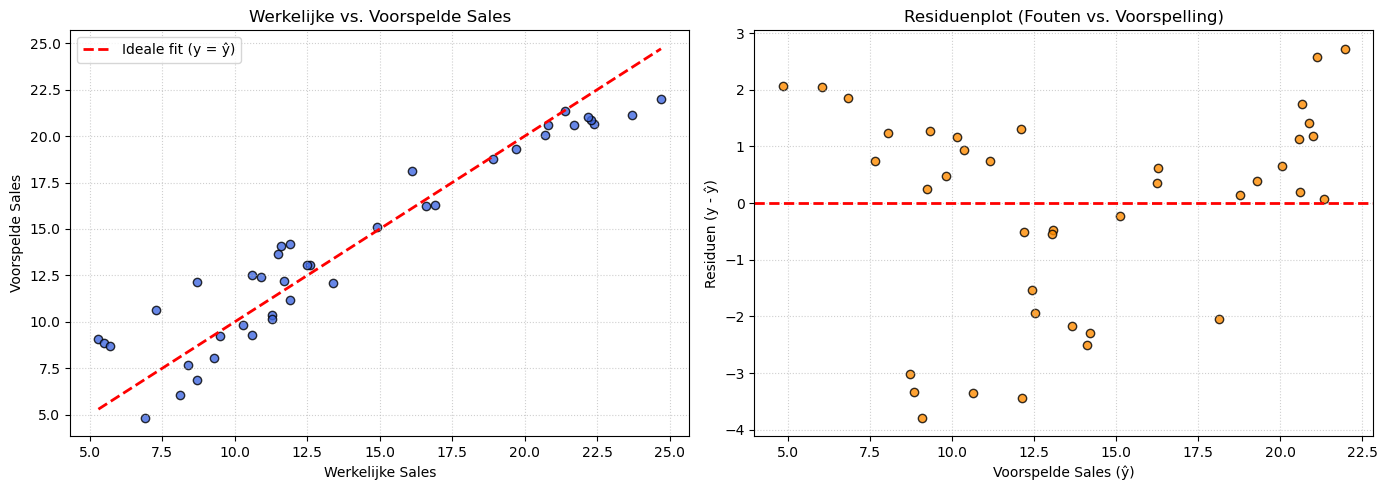

In [21]:
# 7. Residuen-analyse visualisatie
residuen = y_test_f - y_test_pred

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot A: Werkelijke vs. Voorspelde waarden
axes[0].scatter(y_test_f, y_test_pred, color="royalblue", edgecolor="k", alpha=0.8)
axes[0].plot(
    [y_test_f.min(), y_test_f.max()],
    [y_test_f.min(), y_test_f.max()],
    "r--",
    lw=2,
    label="Ideale fit (y = ŷ)",
)
axes[0].set_title("Werkelijke vs. Voorspelde Sales")
axes[0].set_xlabel("Werkelijke Sales")
axes[0].set_ylabel("Voorspelde Sales")
axes[0].legend()
axes[0].grid(True, linestyle=":", alpha=0.6)

# Plot B: Residuenplot
axes[1].scatter(y_test_pred, residuen, color="darkorange", edgecolor="k", alpha=0.8)
axes[1].axhline(0, color="red", linestyle="--", lw=2)
axes[1].set_title("Residuenplot (Fouten vs. Voorspelling)")
axes[1].set_xlabel("Voorspelde Sales (ŷ)")
axes[1].set_ylabel("Residuen (y - ŷ)")
axes[1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

1. Hogere nauwkeurigheid met minder variabelen:
    * Test $R^2$ stijgt van 0.8961 (15 features) naar 0.8983 (2 features).
    * Test RMSE daalt van 1.8113 naar 1.7913.
    * *Inzicht: Het verwijderen van ruisvariabelen verlaagt de variantie van het model, waardoor de voorspelfout op nieuwe data daalt.*
2. Geen overfitting:
    * De trainings-$R^2$ (0.8961) en test-$R^2$ (0.8983) liggen heel dicht bij elkaar. Het model generaliseert goed.
3. Praktische betekenis van MAE / RMSE:
    * Met een $MAE$ van 1.46 zit het model er gemiddeld slechts zo'n $1.460$ verkochte eenheden naast.
4. Principe van spaarzaamheid (Occam's Razor):
    * Het model is van 15 variabelen teruggebracht naar 2, waardoor het in een bedrijfssituatie veel goedkoper, transparanter en robuuster te onderhouden is.

## Stap 8: Voorspelling

**Uitleg:**
  
Als de pipeline geëvalueerd en goedgekeurd is:
1. Slaan we het getrainde model (inclusief preprocessing en beste hyperparameters) op naar schijf met behulp van `joblib.dump`.
2. Laden we het model opnieuw in via `joblib.load` om de productieomgeving te simuleren.   
3. Maken we een voorspelling voor een nieuw, ongezien marketingbudget (bijvoorbeeld: 150k aan TV, 30k aan radio en 20k aan krantenadvertenties).

In [23]:
# Stap 8: Predictie
# 1. Opslaan van het getrainde GridSearchCV-model
joblib.dump(pipeline_f, 'final_advertising_pipeline.pkl')
print("Pipeline succesvol opgeslagen als 'final_advertising_pipeline.pkl'.")

# 2. Inladen van het opgeslagen model
loaded_pipeline = joblib.load('final_advertising_pipeline.pkl')
nieuwe_campagnes = pd.DataFrame(
    [
        {
            "Campagne": "Campagne A (Zwaar TV-focus)",
            "TV": 220.0,
            "radio": 15.0,
        },
        {
            "Campagne": "Campagne B (Gebalanceerd)",
            "TV": 120.0,
            "radio": 40.0,
        },
        {
            "Campagne": "Campagne C (Laag budget)",
            "TV": 30.0,
            "radio": 10.0,
        },
    ]
)

voorspellingen = loaded_pipeline.predict(nieuwe_campagnes[nieuwe_campagnes["TV", "radio"]])
nieuwe_campagnes["Voorspelde Sales (k units)"] = np.round(voorspellingen, 2)

print("\n--- VOORSPELLINGEN VOOR NIEUWE BUDGETTEN ---")
print(
    nieuwe_campagnes[
        ["Campagne", "TV", "radio", "Voorspelde Sales (k units)"]
    ].to_string(index=False)
)

Pipeline succesvol opgeslagen als 'final_advertising_pipeline.pkl'.


KeyError: ('TV', 'radio')

## *Intermezzo: Preprocessing*

| Preprocessing Type | scikit-learn Klasse | Doel / Effect | Gevoelig voor Outliers? | Typisch gebruik |
| :--- | :--- | :--- | :---: | :--- |
| **Z-Score Normalisatie** | `StandardScaler` | \(\mu = 0, \sigma = 1\) | Ja | **Lineaire Regressie, Ridge, Lasso, ElasticNet, PCA** |
| **Bereik Herschaling** | `MinMaxScaler` | Waarden tussen \([0, 1]\) | Heel gevoelig | KNN, Neural Networks, Image processing |
| **Robuuste Schaling** | `RobustScaler` | Mediaan \(= 0\), schaalt via IQR | **Nee (zeer robuust)** | Datasets met zware uitschieters |
| **Normale Transformatie** | `PowerTransformer` | Maakt scheve verdeling symmetrisch | Matig | Zwaar scheve data (skewed) bij regressiemodellen |
| **Rij-vector Schaling** | `Normalizer` | Vectorlengte per sample \(= 1\) | Nee (werkt per rij) | Tekstanalyse (TF-IDF), Cosine similarity |
| **Discretisatie** | `KBinsDiscretizer` | Maakt van continu \(\to\) discrete bins | Nee | Drempelwaarden en niet-lineaire trapsgewijze verbanden |